<a href="https://colab.research.google.com/github/Veniveni123/CSA47-DEEP-LEARNING/blob/main/LAB%201-10/Experiment%207%3A%20Perceptron%20and%20Forward%20Propagation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Loan Perceptron Weight Updates per Epoch:
Epoch  1: w = [0.157 0.117], b = -0.1, Misclassified = 1
Epoch  2: w = [0.157 0.117], b = -0.1, Misclassified = 0


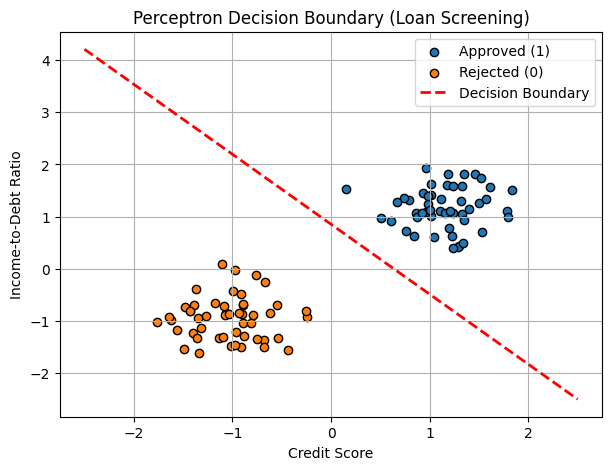


XOR Final Epoch Misclassifications: 4/4 (Does not converge)


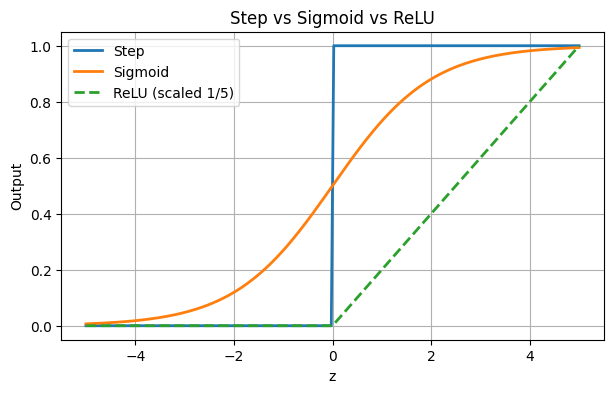

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

def step(z):
    return np.where(z >= 0, 1, 0)

def train_perceptron(X, y, lr=0.1, epochs=25):
    w = np.zeros(X.shape[1])
    b = 0.0
    history = []
    for ep in range(epochs):
        errors = 0
        for xi, yi in zip(X, y):
            pred = step(np.dot(w, xi) + b)
            err = yi - pred
            if err != 0:
                w += lr * err * xi
                b += lr * err
                errors += 1
        history.append((ep + 1, w.copy(), round(b, 3), errors))
        if errors == 0:
            break
    return w, b, history

X_pos = np.random.randn(50, 2) * 0.4 + np.array([1.2, 1.2])
X_neg = np.random.randn(50, 2) * 0.4 + np.array([-1.0, -1.0])
X_loan = np.vstack([X_pos, X_neg])
y_loan = np.array([1]*50 + [0]*50)

w_loan, b_loan, hist_loan = train_perceptron(X_loan, y_loan)
print("Loan Perceptron Weight Updates per Epoch:")
for ep, w_ep, b_ep, err in hist_loan:
    print(f"Epoch {ep:2d}: w = {np.round(w_ep, 3)}, b = {b_ep}, Misclassified = {err}")

plt.figure(figsize=(7, 5))
plt.scatter(X_pos[:, 0], X_pos[:, 1], label='Approved (1)', edgecolors='k')
plt.scatter(X_neg[:, 0], X_neg[:, 1], label='Rejected (0)', edgecolors='k')
x_vals = np.linspace(-2.5, 2.5, 100)
y_vals = -(w_loan[0] * x_vals + b_loan) / w_loan[1]
plt.plot(x_vals, y_vals, 'r--', linewidth=2, label='Decision Boundary')
plt.title("Perceptron Decision Boundary (Loan Screening)")
plt.xlabel("Credit Score")
plt.ylabel("Income-to-Debt Ratio")
plt.legend()
plt.grid(True)
plt.show()

X_xor = np.array([[0,0], [0,1], [1,0], [1,1]])
y_xor = np.array([0, 1, 1, 0])
_, _, hist_xor = train_perceptron(X_xor, y_xor, epochs=15)
print(f"\nXOR Final Epoch Misclassifications: {hist_xor[-1][3]}/4 (Does not converge)")

z_vals = np.linspace(-5, 5, 200)
sigmoid = 1 / (1 + np.exp(-z_vals))
relu = np.maximum(0, z_vals)

plt.figure(figsize=(7, 4))
plt.plot(z_vals, step(z_vals), label='Step', linewidth=2)
plt.plot(z_vals, sigmoid, label='Sigmoid', linewidth=2)
plt.plot(z_vals, relu / 5.0, label='ReLU (scaled 1/5)', linewidth=2, linestyle='--')
plt.title("Step vs Sigmoid vs ReLU")
plt.xlabel("z")
plt.ylabel("Output")
plt.legend()
plt.grid(True)
plt.show()